# **MNIST**

Here, we show how to use DISTIL to perform active learning on image classification tasks (MNIST).

## Installation and Imports

In [1]:

import matplotlib.pyplot as plt
import numpy as np
import os
import sys
import torch
import torch.optim as optim
import torch.nn.functional as F

from torch import nn
from torch.autograd import Variable
from torch.utils.data import Dataset, Subset, ConcatDataset, DataLoader
from torchvision import transforms, datasets
from torchvision.datasets import cifar

sys.path.append('distil/')
from distil.active_learning_strategies import GLISTER, BADGE, EntropySampling, RandomSampling   # All active learning strategies showcased in this example
from distil.utils.models.resnet import ResNet18                                                 # The model used in our image classification example
from distil.utils.train_helper import data_train                                                # A utility training class provided by DISTIL
from distil.utils.utils import LabeledToUnlabeledDataset                                        # A utility wrapper class that removes labels from labeled PyTorch dataset objects

## Preparing MNIST

Description of the MNIST Dataset

In [2]:
# Dataset name
data_set_name = 'MNIST'
download_path = '.'

# Normalization parameters for MNIST (mean and std of grayscale digits)
mean = (0.1307,)
std = (0.3081,)

# Transforms for MNIST
mnist_training_transform = transforms.Compose([
    transforms.RandomCrop(28, padding=4),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

mnist_test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Download MNIST dataset and apply transforms
mnist_full_train = datasets.MNIST(download_path, train=True, download=True, transform=mnist_training_transform)
mnist_test = datasets.MNIST(download_path, train=False, download=True, transform=mnist_test_transform)

# Get image dimension
dim = np.shape(mnist_full_train[0][0])  # should be [1, 28, 28]

# Split into labeled and unlabeled datasets
train_size = 1000
mnist_train = Subset(mnist_full_train, list(range(train_size)))
mnist_unlabeled = Subset(mnist_full_train, list(range(train_size, len(mnist_full_train))))


# Define the number of active learning rounds to conduct, the budget, and the number of classes in MNIST
nclasses = 10
n_rounds = 9
budget = 500 

## Preparing the Model

Here, we use DISTIL's provided implementation of the [ResNet-18](https://arxiv.org/abs/1512.03385) architecture. We also create a model directory to store trained models in this example.

In [9]:
net = ResNet18(num_classes=nclasses, channels=1)
base_dir = "models"
os.makedirs(base_dir, exist_ok = True)
model_directory = os.path.join(base_dir, 'base_model.pth')

## Training an Initial Model
Here, we train an initial model. We do so by creating a training loop object on the initial seed set, the model architecture, and a list of provided arguments. We then save the initial model. Note: If you've already run the first cell, then you can simply run the second cell.

In [10]:
# Specify additional training parameters. Here, we set the maximum number of epochs of training to 300, 
# the learning rate to 0.01, the batch size to 20, the maximum train accuracy of training to 0.99, and 
# the optimizer to stochastic gradient descent.
args = {'n_epoch':300, 'lr':float(0.01), 'batch_size':20, 'max_accuracy':0.99, 'optimizer':'sgd'} 
dt = data_train(mnist_train, net, args)
clf = dt.train()
torch.save(clf.state_dict(), model_directory)

Training..
Epoch: 26 Training accuracy: 0.99


In [6]:
base_dir = "models"
model_directory = os.path.join(base_dir, 'base_model.pth')
net.load_state_dict(torch.load(model_directory))
clf = net

/tmp/ipykernel_40552/3642089891.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  net.load_state_dict(torch.load(model_directory))


## Active Learning Strategies

Here, we show examples of a couple active learning strategies being used in the setting of image classification.

### Random Sampling
This strategy is often used as a baseline, where we pick a subset of unlabeled points randomly. Here, we create a instance of `distil.active_learning_strategies.random_sampling.RandomSampling` by passing following parameters:

**training_dataset** – The labeled dataset, which has a PyTorch interface that returns a tensor of data and a tensor of labels OR a dictionary with a "labels" key.

**unlabeled_dataset** – The unlabeled dataset, which has a PyTorch interface that returns a tensor of data OR a dictionary.

**net** – Model architecture used for training. Could be instance of models defined in distil.utils.models or something similar (in this instance, a Huggingface transformer).

**nclasses** – No. of classes in the dataset

**args**– This dictionary should have ‘batch_size’ as a key. 'batch_size' should be such that one can exploit the benefits of tensorization while honouring the resourse constraits. This ‘batch_size’ therefore can be different than the one used for training.


In [ ]:
from copy import deepcopy

initial_mnist_train = deepcopy(mnist_train)
initial_unlabeled = deepcopy(mnist_unlabeled)
# Loop over each class
for target_class in range(nclasses):
    print(f"\n========= Class {target_class} =========")

    # Restrict test set to only this class
    class_test_indices = [i for i, (_, label) in enumerate(mnist_test) if label == target_class]
    class_test_set = Subset(mnist_test, class_test_indices)

    # Reinitialize and load the pretrained model
    base_dir = "models"
    model_directory = os.path.join(base_dir, 'base_model.pth')
    net.load_state_dict(torch.load(model_directory))
    clf = net

    # Set up training args again
    args = {'n_epoch': 300, 'lr': 0.01, 'batch_size': 20, 'max_accuracy': 0.99, 'optimizer': 'sgd'}
    mnist_train = deepcopy(initial_mnist_train)
    dt = data_train(mnist_train, net, args)

    # Create AL strategy instance
    strategy_args = {'batch_size': 20}
    mnist_unlabeled = deepcopy(initial_unlabeled)
    strategy = RandomSampling(mnist_train, LabeledToUnlabeledDataset(mnist_unlabeled), net, nclasses, strategy_args)
    strategy.update_model(net)

    # Track accuracy across rounds
    acc = np.zeros(n_rounds)
    acc[0] = dt.get_acc_on_set(class_test_set)
    print(f"Initial test accuracy on class {target_class}: {round(acc[0]*100, 2)}%")

    # Active Learning Loop
    for rd in range(1, n_rounds):
        print('-------------------------------------------------')
        print(f'Round {rd} for class {target_class}')
        print('-------------------------------------------------')

        # Disable augmentation for selection
        mnist_full_train.transform = mnist_test_transform
        idx = strategy.select(budget)
        mnist_full_train.transform = mnist_training_transform

        # Add selected samples to training set
        selected_subset = Subset(mnist_unlabeled, idx)
        mnist_train = ConcatDataset([mnist_train, selected_subset])

        # Update unlabeled pool
        remaining_indices = list(set(range(len(mnist_unlabeled))) - set(idx))
        mnist_unlabeled = Subset(mnist_unlabeled, remaining_indices)

        print("Number of training samples:", len(mnist_train))

        # Update strategy and training data
        strategy.update_data(mnist_train, LabeledToUnlabeledDataset(mnist_unlabeled))
        dt.update_data(mnist_train)

        # Retrain model
        clf = dt.train()
        strategy.update_model(clf)

        # Evaluate on current class only
        acc[rd] = dt.get_acc_on_set(class_test_set)
        print(f"Accuracy on class {target_class}: {round(acc[rd]*100, 2)}%")

    print(f"Training completed for class {target_class}")

    # Save accuracy results
    dir = os.path.join('results', data_set_name, 'baseline')
    os.makedirs(dir, exist_ok=True)
    save_path = os.path.join(dir, f'class_{target_class}_random.txt')
    with open(save_path, 'w') as f:
        for a in acc:
            f.write(f"{a}\n")
    print(f"Saved class-wise accuracy to: {save_path}")


========= Class 0 =========


/tmp/ipykernel_40552/386251632.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  net.load_state_dict(torch.load(model_directory))


Initial test accuracy on class 0: 98.47%
-------------------------------------------------
Round 1 for class 0
-------------------------------------------------
Number of training samples: 1500
Training..
Epoch: 30 Training accuracy: 0.992
Accuracy on class 0: 98.78%
-------------------------------------------------
Round 2 for class 0
-------------------------------------------------
Number of training samples: 2000
Training..


### Entropy Sampling
A very basic strategy to select unlabeled points is entropy sampling, where we select samples about which the model is most uncertain by measuring the entropy of the class prediction. Hence, a valid strategy is to select those points in the unlabeled set with highest entropy (maximum uncertainty). Specifically, let $z = f(x)$ be the output from the model with class $i$ having score $z_i$. By applying a softmax, we obtain probabilities that we can use: 

$$\sigma(z)_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$ 

Using the softmax probabilities, entropy sampling selects a subset based on the following objective:

 $$\text{argmin}_{A \subseteq U, |A| = k} \sum_{x \in A} \left[ -\sum_j \sigma(z)_j*\log(\sigma(z)_j) \right]$$

Here, we create a instance of `distil.active_learning_strategies.entropy_sampling.EntropySampling` with the same parameters passed to `distil.active_learning_strategies.random_sampling.RandomSampling`.

**Reloading Base Model & Data**

We make sure the fixture is the same by repeating the same setup.

In [28]:
# Dataset name
data_set_name = 'MNIST'
download_path = '.'

# Normalization parameters for MNIST (mean and std of grayscale digits)
mean = (0.1307,)
std = (0.3081,)

# Transforms for MNIST
mnist_training_transform = transforms.Compose([
    transforms.RandomCrop(28, padding=4),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

mnist_test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Download MNIST dataset and apply transforms
mnist_full_train = datasets.MNIST(download_path, train=True, download=True, transform=mnist_training_transform)
mnist_test = datasets.MNIST(download_path, train=False, download=True, transform=mnist_test_transform)

# Get image dimension
dim = np.shape(mnist_full_train[0][0])  # should be [1, 28, 28]

# Split into labeled and unlabeled datasets
train_size = 1000
mnist_train = Subset(mnist_full_train, list(range(train_size)))
mnist_unlabeled = Subset(mnist_full_train, list(range(train_size, len(mnist_full_train))))


# Define the number of active learning rounds to conduct, the budget, and the number of classes in MNIST
nclasses = 10
n_rounds = 9
budget = 500 

net = ResNet18(num_classes=nclasses, channels=1)

In [8]:
base_dir = "models"
model_directory = os.path.join(base_dir, 'base_model.pth')
net.load_state_dict(torch.load(model_directory))
clf = net

/tmp/ipykernel_54779/3642089891.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  net.load_state_dict(torch.load(model_directory))


RuntimeError: Error(s) in loading state_dict for ResNet:
	Missing key(s) in state_dict: "conv1.weight", "bn1.weight", "bn1.bias", "bn1.running_mean", "bn1.running_var", "layer1.0.conv1.weight", "layer1.0.bn1.weight", "layer1.0.bn1.bias", "layer1.0.bn1.running_mean", "layer1.0.bn1.running_var", "layer1.0.conv2.weight", "layer1.0.bn2.weight", "layer1.0.bn2.bias", "layer1.0.bn2.running_mean", "layer1.0.bn2.running_var", "layer1.1.conv1.weight", "layer1.1.bn1.weight", "layer1.1.bn1.bias", "layer1.1.bn1.running_mean", "layer1.1.bn1.running_var", "layer1.1.conv2.weight", "layer1.1.bn2.weight", "layer1.1.bn2.bias", "layer1.1.bn2.running_mean", "layer1.1.bn2.running_var", "layer2.0.conv1.weight", "layer2.0.bn1.weight", "layer2.0.bn1.bias", "layer2.0.bn1.running_mean", "layer2.0.bn1.running_var", "layer2.0.conv2.weight", "layer2.0.bn2.weight", "layer2.0.bn2.bias", "layer2.0.bn2.running_mean", "layer2.0.bn2.running_var", "layer2.0.shortcut.0.weight", "layer2.0.shortcut.1.weight", "layer2.0.short

In [ ]:
from copy import deepcopy

initial_mnist_train = deepcopy(mnist_train)
initial_unlabeled = deepcopy(mnist_unlabeled)
# Loop over each class
for target_class in range(nclasses):
    print(f"\n========= Class {target_class} =========")

    # Restrict test set to only this class
    class_test_indices = [i for i, (_, label) in enumerate(mnist_test) if label == target_class]
    class_test_set = Subset(mnist_test, class_test_indices)

    # Reinitialize and load the pretrained model
    base_dir = "models"
    model_directory = os.path.join(base_dir, 'base_model.pth')
    net.load_state_dict(torch.load(model_directory))
    clf = net

    # Set up training args again
    args = {'n_epoch': 300, 'lr': 0.01, 'batch_size': 20, 'max_accuracy': 0.99, 'optimizer': 'sgd'}
    mnist_train = deepcopy(initial_mnist_train)
    dt = data_train(mnist_train, net, args)

    # Create AL strategy instance
    strategy_args = {'batch_size': 20}
    mnist_unlabeled = deepcopy(initial_unlabeled)
    strategy = EntropySampling(mnist_train, LabeledToUnlabeledDataset(mnist_unlabeled), net, nclasses, strategy_args)
    strategy.update_model(net)

    # Track accuracy across rounds
    acc = np.zeros(n_rounds)
    acc[0] = dt.get_acc_on_set(class_test_set)
    print(f"Initial test accuracy on class {target_class}: {round(acc[0]*100, 2)}%")

    # Active Learning Loop
    for rd in range(1, n_rounds):
        print('-------------------------------------------------')
        print(f'Round {rd} for class {target_class}')
        print('-------------------------------------------------')

        # Disable augmentation for selection
        mnist_full_train.transform = mnist_test_transform
        idx = strategy.select(budget)
        mnist_full_train.transform = mnist_training_transform

        # Add selected samples to training set
        selected_subset = Subset(mnist_unlabeled, idx)
        mnist_train = ConcatDataset([mnist_train, selected_subset])

        # Update unlabeled pool
        remaining_indices = list(set(range(len(mnist_unlabeled))) - set(idx))
        mnist_unlabeled = Subset(mnist_unlabeled, remaining_indices)

        print("Number of training samples:", len(mnist_train))

        # Update strategy and training data
        strategy.update_data(mnist_train, LabeledToUnlabeledDataset(mnist_unlabeled))
        dt.update_data(mnist_train)

        # Retrain model
        clf = dt.train()
        strategy.update_model(clf)

        # Evaluate on current class only
        acc[rd] = dt.get_acc_on_set(class_test_set)
        print(f"Accuracy on class {target_class}: {round(acc[rd]*100, 2)}%")

    print(f"Training completed for class {target_class}")

    # Save accuracy results
    dir = os.path.join('results', data_set_name, 'baseline')
    os.makedirs(dir, exist_ok=True)
    save_path = os.path.join(dir, f'class_{target_class}_entropy.txt')
    with open(save_path, 'w') as f:
        for a in acc:
            f.write(f"{a}\n")
    print(f"Saved class-wise accuracy to: {save_path}")

Initial Testing accuracy: 94.95
-------------------------------------------------
Round 1
-------------------------------------------------
Number of training points - 1500
Training..
Epoch: 52 Training accuracy: 0.991
Testing accuracy: 98.63
-------------------------------------------------
Round 2
-------------------------------------------------
Number of training points - 2000
Training..
Epoch: 87 Training accuracy: 0.99
Testing accuracy: 99.14
-------------------------------------------------
Round 3
-------------------------------------------------
Number of training points - 2500
Training..
Epoch: 89 Training accuracy: 0.991
Testing accuracy: 99.44
-------------------------------------------------
Round 4
-------------------------------------------------
Number of training points - 3000
Training..
Epoch: 133 Training accuracy: 0.991
Testing accuracy: 99.5
-------------------------------------------------
Round 5
-------------------------------------------------
Number of trainin

### BADGE
This method is based on the paper [Deep Batch Active Learning by Diverse, Uncertain Gradient Lower Bounds](https://arxiv.org/abs/1906.03671). The strategy is meant to select points that are both diverse (e.g., their embeddings span multiple directions) and uncertain (e.g., their contribution to the loss is large). The following steps are taken:

* Calculate the pseudo-label for each point in the unlabeled set. The pseudo-label is the class with the highest probability.
* Compute the cross-entropy loss for each point in the unlabeled set using this pseudo-label.
* Obtain the resulting loss gradients on the last linear layer of the model for each point. (These are referred to as the hypothesized loss gradients.)
* Using these gradients as a form of embedding for each unlabeled point, run k-means++ initialization on this embedding set, retrieving $k$ centers. Each center is a point from the unlabeled set, and $k$ represents the active learning budget.
* Request labels for the $k$ points whose embeddings were selected.

Here we create a instance of `distil.active_learning_strategies.badge.BADGE` with same parameters passed to `distil.active_learning_strategies.random_sampling.RandomSampling`.

**Reloading Base Model & Data**

In [31]:
# Dataset name
data_set_name = 'MNIST'
download_path = '.'

# Normalization parameters for MNIST (mean and std of grayscale digits)
mean = (0.1307,)
std = (0.3081,)

# Transforms for MNIST
mnist_training_transform = transforms.Compose([
    transforms.RandomCrop(28, padding=4),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

mnist_test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Download MNIST dataset and apply transforms
mnist_full_train = datasets.MNIST(download_path, train=True, download=True, transform=mnist_training_transform)
mnist_test = datasets.MNIST(download_path, train=False, download=True, transform=mnist_test_transform)

# Get image dimension
dim = np.shape(mnist_full_train[0][0])  # should be [1, 28, 28]

# Split into labeled and unlabeled datasets
train_size = 1000
mnist_train = Subset(mnist_full_train, list(range(train_size)))
mnist_unlabeled = Subset(mnist_full_train, list(range(train_size, len(mnist_full_train))))


# Define the number of active learning rounds to conduct, the budget, and the number of classes in MNIST
nclasses = 10
n_rounds = 9
budget = 500 

In [32]:
base_dir = "models"
model_directory = os.path.join(base_dir, 'base_model.pth')
net.load_state_dict(torch.load(model_directory))
clf = net

/tmp/ipykernel_32748/3642089891.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  net.load_state_dict(torch.load(model_directory))


In [ ]:
from copy import deepcopy

initial_mnist_train = deepcopy(mnist_train)
initial_unlabeled = deepcopy(mnist_unlabeled)
# Loop over each class
for target_class in range(nclasses):
    print(f"\n========= Class {target_class} =========")

    # Restrict test set to only this class
    class_test_indices = [i for i, (_, label) in enumerate(mnist_test) if label == target_class]
    class_test_set = Subset(mnist_test, class_test_indices)

    # Reinitialize and load the pretrained model
    base_dir = "models"
    model_directory = os.path.join(base_dir, 'base_model.pth')
    net.load_state_dict(torch.load(model_directory))
    clf = net

    # Set up training args again
    args = {'n_epoch': 300, 'lr': 0.01, 'batch_size': 20, 'max_accuracy': 0.99, 'optimizer': 'sgd'}
    mnist_train = deepcopy(initial_mnist_train)
    dt = data_train(mnist_train, net, args)

    # Create AL strategy instance
    strategy_args = {'batch_size': 20}
    mnist_unlabeled = deepcopy(initial_unlabeled)
    strategy = BADGE(mnist_train, LabeledToUnlabeledDataset(mnist_unlabeled), net, nclasses, strategy_args)
    strategy.update_model(net)

    # Track accuracy across rounds
    acc = np.zeros(n_rounds)
    acc[0] = dt.get_acc_on_set(class_test_set)
    print(f"Initial test accuracy on class {target_class}: {round(acc[0]*100, 2)}%")

    # Active Learning Loop
    for rd in range(1, n_rounds):
        print('-------------------------------------------------')
        print(f'Round {rd} for class {target_class}')
        print('-------------------------------------------------')

        # Disable augmentation for selection
        mnist_full_train.transform = mnist_test_transform
        idx = strategy.select(budget)
        mnist_full_train.transform = mnist_training_transform

        # Add selected samples to training set
        selected_subset = Subset(mnist_unlabeled, idx)
        mnist_train = ConcatDataset([mnist_train, selected_subset])

        # Update unlabeled pool
        remaining_indices = list(set(range(len(mnist_unlabeled))) - set(idx))
        mnist_unlabeled = Subset(mnist_unlabeled, remaining_indices)

        print("Number of training samples:", len(mnist_train))

        # Update strategy and training data
        strategy.update_data(mnist_train, LabeledToUnlabeledDataset(mnist_unlabeled))
        dt.update_data(mnist_train)

        # Retrain model
        clf = dt.train()
        strategy.update_model(clf)

        # Evaluate on current class only
        acc[rd] = dt.get_acc_on_set(class_test_set)
        print(f"Accuracy on class {target_class}: {round(acc[rd]*100, 2)}%")

    print(f"Training completed for class {target_class}")

    # Save accuracy results
    dir = os.path.join('results', data_set_name, 'baseline')
    os.makedirs(dir, exist_ok=True)
    save_path = os.path.join(dir, f'class_{target_class}_badge.txt')
    with open(save_path, 'w') as f:
        for a in acc:
            f.write(f"{a}\n")
    print(f"Saved class-wise accuracy to: {save_path}")

Initial Testing accuracy: 94.95
-------------------------------------------------
Round 1
-------------------------------------------------
Number of training points - 1500
Training..
Epoch: 42 Training accuracy: 0.991
Testing accuracy: 98.58
-------------------------------------------------
Round 2
-------------------------------------------------
Number of training points - 2000
Training..
Epoch: 74 Training accuracy: 0.991
Testing accuracy: 99.13
-------------------------------------------------
Round 3
-------------------------------------------------
Number of training points - 2500
Training..
Epoch: 75 Training accuracy: 0.991
Testing accuracy: 99.17
-------------------------------------------------
Round 4
-------------------------------------------------
Number of training points - 3000
Training..
Epoch: 111 Training accuracy: 0.992
Testing accuracy: 99.59
-------------------------------------------------
Round 5
-------------------------------------------------
Number of train

### GLISTER
This is implemetation of GLISTER-ACTIVE from the paper [GLISTER: Generalization based Data Subset Selection for Efficient and Robust Learning](https://arxiv.org/abs/2012.10630). `GLISTER` tries to solve the following bi-level optimisation problem:
\begin{equation*}
\overbrace{\underset{{S \subseteq {\mathcal U}, |S| \leq k}}{\operatorname{argmax\hspace{0.7mm}}} LL_V(\underbrace{\underset{\theta}{\operatorname{argmax\hspace{0.7mm}}} LL_T( \theta, S)}_{inner-level}, {\mathcal V})}^{outer-level}
\end{equation*}
where is $S$ is set of points selected at each round, ${\mathcal V}$ could be a dedicated validation set with labeled points or could be union of labeled and unlabeled points with hypothesized labels, and $k$ is the budget.

Solving this problem directly is almost intractable due to the bi-level nature (e.g., repeatedly having to solve the inner problem); therefore, GLISTER resorts to one-step approximations. To start, we set $S^0$ as the empty set and incrementally build it as $S^k = S^{k-1} \cup e$, where $e$ is $\underset{e}{\operatorname{argmax\hspace{0.7mm}}} G_{\theta}(e | S^k)$, defined below: $$G_{\theta}(e | S^k) = LL_{V}(\theta^{k}, {\mathcal V})$$

Concurrently, GLISTER updates the model parameters via the aforementioned one-step approximation after each greedy selection, which allows for recalculation of $G_{\theta}$:

$$\theta^k \leftarrow \theta^{k-1} + \eta \nabla_{\theta} LL_T(\hat{\theta}, e),$$ 

where $\hat{\theta}$ are the parameters of the model at the begining of the selection.

To prevent overfitting, we can add regularization to GLISTER, which can be set by **_typeOf_**. **_typeOf_** can be set to **None** for normal GLISTER (default), **'Rand'** for replacing **_lam_** fraction of points with random points, **'Diversity'** for adding a diversity set function while computing gain, and **'FacLoc'** for adding a facility location set function while computing gain. **_lam_** for both **'Diversity'** and **'FacLoc'** determines the weightage given to them while computing the gain.

Here, we create a instance of `distil.active_learning_strategies.glister.GLISTER` with the same parameters passed to `distil.active_learning_strategies.random_sampling.RandomSampling`. Additionally, we add to the **_args_** dictionary the required keys ‘batch_size’ and ‘lr’. ‘lr’ should be the learning rate used for training. Lastly, the following parameters can be passed as previously described:

**validation_dataset (torch.utils.data.Dataset, optional)** – An optional validation dataset.

**typeOf (str, optional)** – Determines the type of regularizer to be used. The default is **None**. For a random regularizer, use **‘Rand’**. To use the facility location set function as a regularizer, use **‘FacLoc’**. To use a diversity set function as a regularizer, use **‘Diversity’**.

**lam (float, optional)** – Determines the amount of regularization to be applied. Mandatory if is not **_typeOf_=None** and, by default, is set to **None**. For random regularizers, use values between 0 and 1 as it determines fraction of points replaced by random points. For both **‘Diversity’** and **‘FacLoc’**, **_lam_** determines the weightage given to them while computing the gain.

**kernel_batch_size (int, optional)** – For the **'Diversity'** and **'FacLoc'** regularizer versions, a similarity kernel is computed, which entails creating a 3-D Torch tensor of dimensions $kernel\_batch\_size^{2}\times(feature\ dimension)$. Again, **_kernel_batch_size_** should be such that one can exploit the benefits of tensorization while honouring the resourse constraints.

**Reloading Base Model & Data**

In [4]:
# Dataset name
data_set_name = 'MNIST'
download_path = '.'

# Normalization parameters for MNIST (mean and std of grayscale digits)
mean = (0.1307,)
std = (0.3081,)

# Transforms for MNIST
mnist_training_transform = transforms.Compose([
    transforms.RandomCrop(28, padding=4),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

mnist_test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Download MNIST dataset and apply transforms
mnist_full_train = datasets.MNIST(download_path, train=True, download=True, transform=mnist_training_transform)
mnist_test = datasets.MNIST(download_path, train=False, download=True, transform=mnist_test_transform)

# Get image dimension
dim = np.shape(mnist_full_train[0][0])  # should be [1, 28, 28]

# Split into labeled and unlabeled datasets
train_size = 1000
mnist_train = Subset(mnist_full_train, list(range(train_size)))
mnist_unlabeled = Subset(mnist_full_train, list(range(train_size, len(mnist_full_train))))


# Define the number of active learning rounds to conduct, the budget, and the number of classes in MNIST
nclasses = 10
n_rounds = 9
budget = 500 

net = ResNet18(num_classes=nclasses, channels=1)

In [5]:
base_dir = "models"
model_directory = os.path.join(base_dir, 'base_model.pth')
net.load_state_dict(torch.load(model_directory))
clf = net

/tmp/ipykernel_36240/3642089891.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  net.load_state_dict(torch.load(model_directory))


In [ ]:
from copy import deepcopy

initial_mnist_train = deepcopy(mnist_train)
initial_unlabeled = deepcopy(mnist_unlabeled)
# Loop over each class
for target_class in range(nclasses):
    print(f"\n========= Class {target_class} =========")

    # Restrict test set to only this class
    class_test_indices = [i for i, (_, label) in enumerate(mnist_test) if label == target_class]
    class_test_set = Subset(mnist_test, class_test_indices)

    # Reinitialize and load the pretrained model
    base_dir = "models"
    model_directory = os.path.join(base_dir, 'base_model.pth')
    net.load_state_dict(torch.load(model_directory))
    clf = net

    # Set up training args again
    args = {'n_epoch': 300, 'lr': 0.01, 'batch_size': 20, 'max_accuracy': 0.99, 'optimizer': 'sgd'}
    mnist_train = deepcopy(initial_mnist_train)
    dt = data_train(mnist_train, net, args)

    # Create AL strategy instance
    strategy_args = {'batch_size': 20}
    mnist_unlabeled = deepcopy(initial_unlabeled)
    strategy = RandomSampling(mnist_train, LabeledToUnlabeledDataset(mnist_unlabeled), net, nclasses, strategy_args)
    strategy.update_model(net)

    # Track accuracy across rounds
    acc = np.zeros(n_rounds)
    acc[0] = dt.get_acc_on_set(class_test_set)
    print(f"Initial test accuracy on class {target_class}: {round(acc[0]*100, 2)}%")

    # Active Learning Loop
    for rd in range(1, n_rounds):
        print('-------------------------------------------------')
        print(f'Round {rd} for class {target_class}')
        print('-------------------------------------------------')

        # Disable augmentation for selection
        mnist_full_train.transform = mnist_test_transform
        idx = strategy.select(budget)
        mnist_full_train.transform = mnist_training_transform

        # Add selected samples to training set
        selected_subset = Subset(mnist_unlabeled, idx)
        mnist_train = ConcatDataset([mnist_train, selected_subset])

        # Update unlabeled pool
        remaining_indices = list(set(range(len(mnist_unlabeled))) - set(idx))
        mnist_unlabeled = Subset(mnist_unlabeled, remaining_indices)

        print("Number of training samples:", len(mnist_train))

        # Update strategy and training data
        strategy.update_data(mnist_train, LabeledToUnlabeledDataset(mnist_unlabeled))
        dt.update_data(mnist_train)

        # Retrain model
        clf = dt.train()
        strategy.update_model(clf)

        # Evaluate on current class only
        acc[rd] = dt.get_acc_on_set(class_test_set)
        print(f"Accuracy on class {target_class}: {round(acc[rd]*100, 2)}%")

    print(f"Training completed for class {target_class}")

    # Save accuracy results
    dir = os.path.join('results', data_set_name, 'baseline')
    os.makedirs(dir, exist_ok=True)
    save_path = os.path.join(dir, f'class_{target_class}_glister.txt')
    with open(save_path, 'w') as f:
        for a in acc:
            f.write(f"{a}\n")
    print(f"Saved class-wise accuracy to: {save_path}")

Initial Testing accuracy: 94.95
-------------------------------------------------
Round 1
-------------------------------------------------
Number of training points - 1500
Training..
Epoch: 40 Training accuracy: 0.993
Testing accuracy: 97.34
-------------------------------------------------
Round 2
-------------------------------------------------
Number of training points - 2000
Training..
Epoch: 37 Training accuracy: 0.992
Testing accuracy: 98.42
-------------------------------------------------
Round 3
-------------------------------------------------
Number of training points - 2500
Training..
Epoch: 56 Training accuracy: 0.99
Testing accuracy: 99.06
-------------------------------------------------
Round 4
-------------------------------------------------
Number of training points - 3000
Training..
Epoch: 91 Training accuracy: 0.99
Testing accuracy: 99.49
-------------------------------------------------
Round 5
-------------------------------------------------
Number of training

In [13]:
from copy import deepcopy
import os
from torchvision import datasets
import torch
import numpy as np

# Reload full datasets with correct transforms
full_mnist_train = datasets.MNIST(download_path, train=True, download=True, transform=mnist_training_transform)
full_mnist_test = datasets.MNIST(download_path, train=False, download=True, transform=mnist_test_transform)

# Load and prepare model
base_dir = "models"
model_path = os.path.join(base_dir, 'base_model.pth')
net.load_state_dict(torch.load(model_path))
model = deepcopy(net)
model.load_state_dict(torch.load(model_path))

# Training arguments
args = {'n_epoch': 300, 'lr': 0.01, 'batch_size': 20, 'max_accuracy': 0.99, 'optimizer': 'sgd'}

# Train on full dataset
dt = data_train(full_mnist_train, model, args)
dt.update_data(full_mnist_train)
trained_model = dt.train()

# Evaluate per-class accuracy on test set
test_loader = torch.utils.data.DataLoader(full_mnist_test, batch_size=100, shuffle=False)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
trained_model.to(device)
trained_model.eval()

# Initialize class-wise counters
nclasses = 10
correct_per_class = [0 for _ in range(nclasses)]
total_per_class = [0 for _ in range(nclasses)]

# Evaluate
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = trained_model(images)
        _, predicted = torch.max(outputs.data, 1)
        for i in range(len(labels)):
            label = labels[i].item()
            total_per_class[label] += 1
            correct_per_class[label] += (predicted[i].item() == label)

# Calculate and save per-class accuracy
per_class_accuracy = [correct / total for correct, total in zip(correct_per_class, total_per_class)]
ref_dir = os.path.join('results', data_set_name, 'baseline')
os.makedirs(ref_dir, exist_ok=True)

for cls, acc in enumerate(per_class_accuracy):
    acc_path = os.path.join(ref_dir, f'class_{cls}_fully_supervised.txt')
    with open(acc_path, 'w') as f:
        f.write(str(acc))
    print(f"Saved fully supervised accuracy for class {cls}: {round(acc * 100, 2)}% → {acc_path}")


/tmp/ipykernel_54779/2502801687.py:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  net.load_state_dict(torch.load(model_path))
/tmp/ipykernel_54779/2502801687.py:16: Futur

Training..
Epoch: 25 Training accuracy: 0.989
Saved fully supervised accuracy for class 0: 99.18% → results/MNIST/baseline/class_0_fully_supervised.txt
Saved fully supervised accuracy for class 1: 99.82% → results/MNIST/baseline/class_1_fully_supervised.txt
Saved fully supervised accuracy for class 2: 98.93% → results/MNIST/baseline/class_2_fully_supervised.txt
Saved fully supervised accuracy for class 3: 99.7% → results/MNIST/baseline/class_3_fully_supervised.txt
Saved fully supervised accuracy for class 4: 99.69% → results/MNIST/baseline/class_4_fully_supervised.txt
Saved fully supervised accuracy for class 5: 99.1% → results/MNIST/baseline/class_5_fully_supervised.txt
Saved fully supervised accuracy for class 6: 98.96% → results/MNIST/baseline/class_6_fully_supervised.txt
Saved fully supervised accuracy for class 7: 99.61% → results/MNIST/baseline/class_7_fully_supervised.txt
Saved fully supervised accuracy for class 8: 99.28% → results/MNIST/baseline/class_8_fully_supervised.txt
Sa

## Visualizing the Results

If all strategies have run to completion, you can run the following cell to view the results.

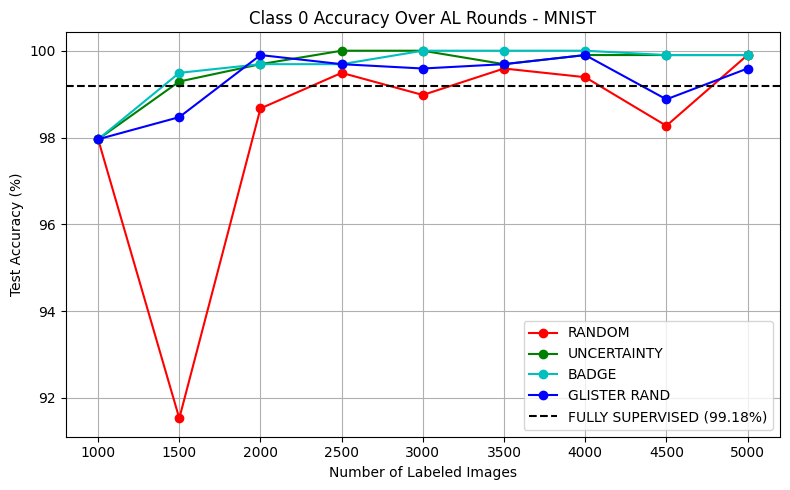

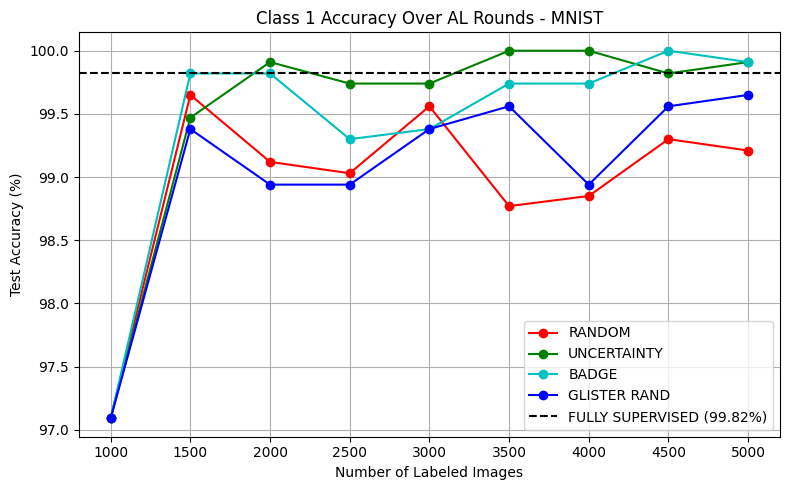

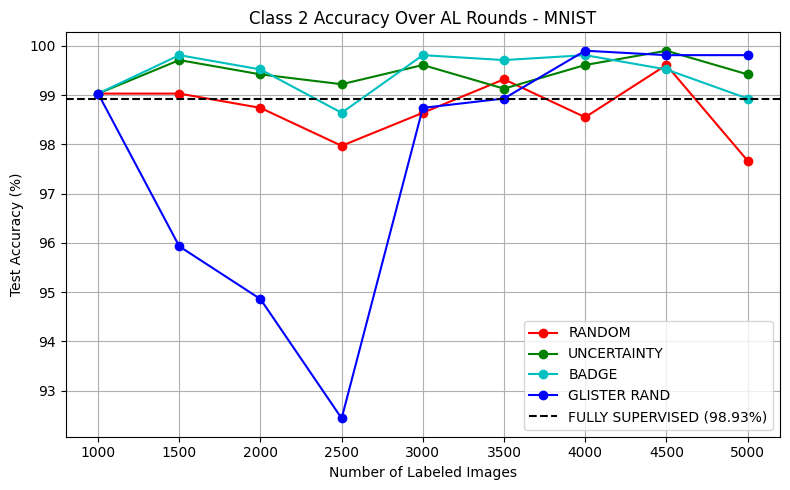

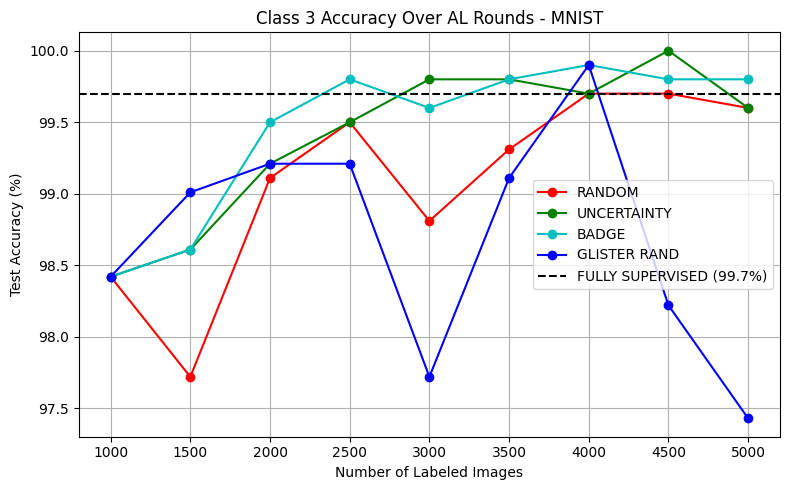

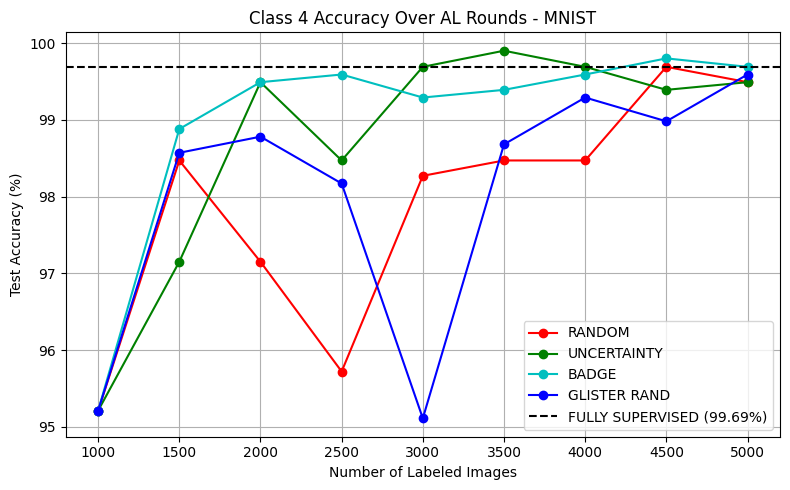

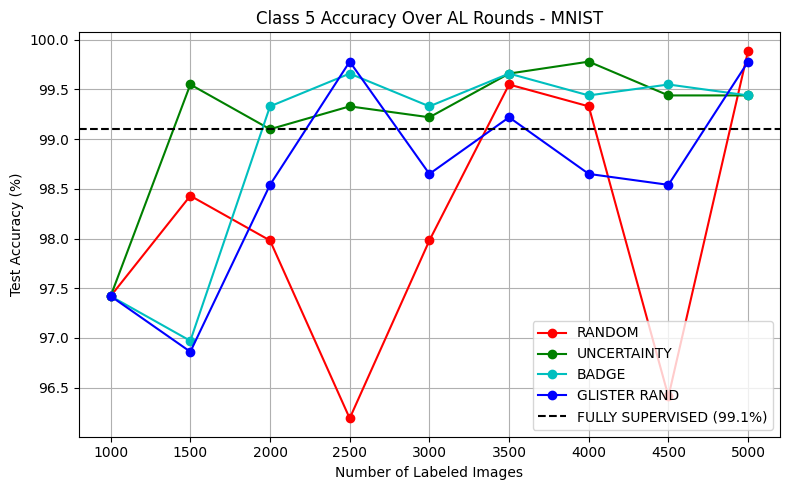

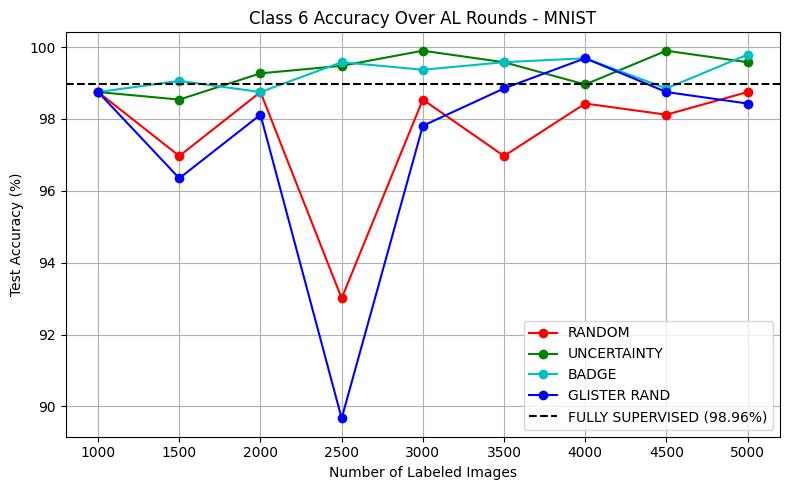

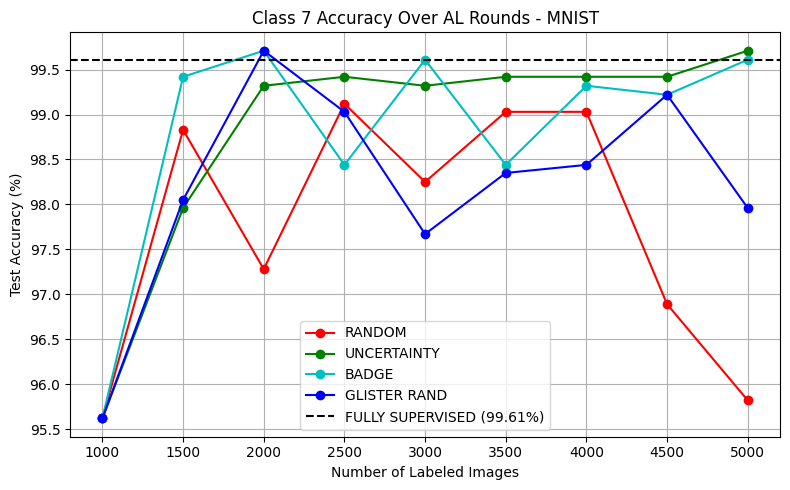

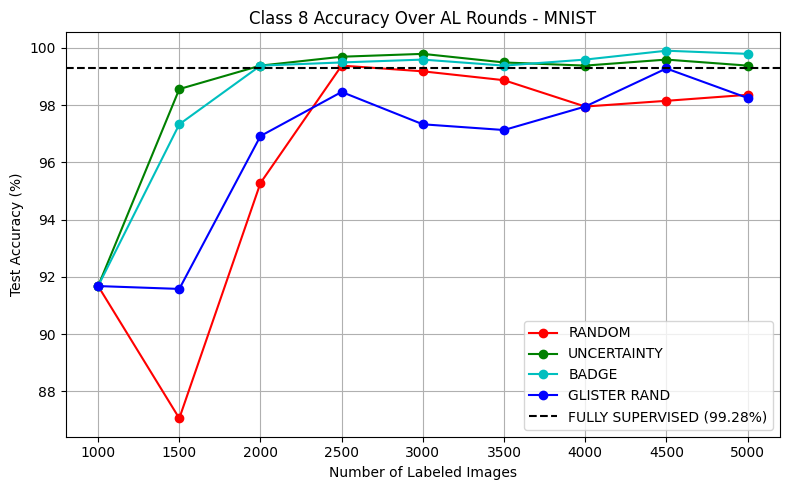

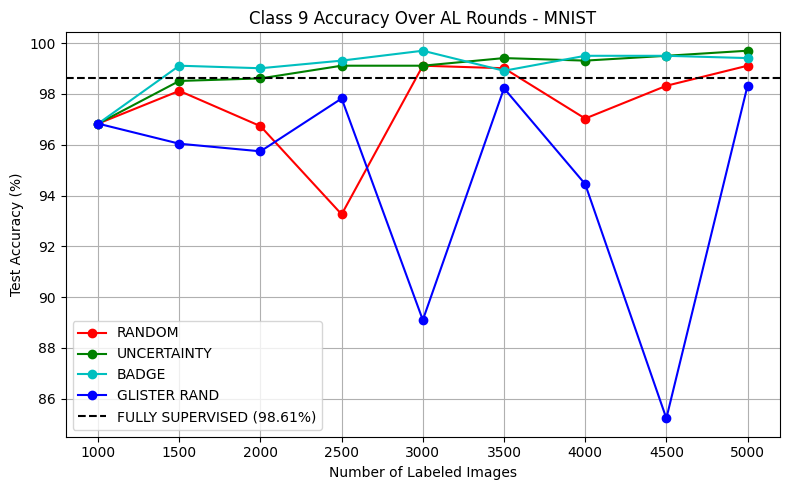

In [14]:
import os
import numpy as np
import matplotlib.pyplot as plt

dir = os.path.join('results', data_set_name, 'baseline')

# X-axis: number of labeled samples after each round
x_axis = np.array([train_size + budget * i for i in range(n_rounds)])

# Strategies to compare
strategies = ['random', 'entropy', 'badge', 'glister']
colors = {'random': 'r', 'entropy': 'g', 'badge': 'c', 'glister': 'b'}
labels = {'random': 'RANDOM', 'entropy': 'UNCERTAINTY', 'badge': 'BADGE', 'glister': 'GLISTER RAND'}

# Plot class-wise curves
for cls in range(nclasses):
    plt.figure(figsize=(8, 5))
    
    # Load fully supervised accuracy for this class
    fs_path = os.path.join(dir, f'class_{cls}_fully_supervised.txt')
    if os.path.exists(fs_path):
        with open(fs_path, 'r') as f:
            fs_acc = round(float(f.read().strip()) * 100, 2)
    else:
        print(f"Missing fully supervised file: {fs_path}")
        fs_acc = None

    # Plot each strategy
    for strat in strategies:
        file_path = os.path.join(dir, f'class_{cls}_{strat}.txt')
        if not os.path.exists(file_path):
            print(f"Missing file: {file_path}")
            continue

        with open(file_path, 'r') as f:
            acc_list = [round(float(line.strip()) * 100, 2) for line in f]
            plt.plot(x_axis, acc_list, label=labels[strat], marker='o', color=colors[strat])

    # Add horizontal line for fully supervised accuracy (per class)
    if fs_acc is not None:
        plt.axhline(y=fs_acc, color='k', linestyle='--', label=f'FULLY SUPERVISED ({fs_acc}%)')

    plt.title(f'Class {cls} Accuracy Over AL Rounds - MNIST')
    plt.xlabel('Number of Labeled Images')
    plt.ylabel('Test Accuracy (%)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
